# EDA: пары аптамер-белок и шортлист докинга

Смотрел таблицы, на которых учатся генератор и скрининг связывания.

- `Aptamer-Generation/data/train_dna_dataset.csv`
- `Aptamer-Generation/data/train_rna_dataset.csv`
- `Aptamer-Validation/docking_candidates/candidates_for_docking.csv`
- `Aptamer-Validation/docking_results/final_ranked_candidates_hdock.csv`

Исходный файл `Aptamers_and_targets.csv`, из которого скрипт `preprocess_and_split.py` собирает негативы, в репозитории нет. Тестовые CSV тоже нет. Ниже описаны те таблицы, которые реально лежат в репозитории.

In [1]:
import json
from pathlib import Path

import run_eda
from IPython.display import Image, display

run_eda.main()
summary = json.loads(Path("eda_summary.json").read_text(encoding="utf-8"))
print("DNA", summary["dna"]["rows"], "rows, labels", summary["dna"]["label_counts"])
print("RNA", summary["rna"]["rows"], "rows, labels", summary["rna"]["label_counts"])
print("candidates", summary["candidates"]["rows"], "docking rows", summary["docking"]["rows"])

C:\Users\ebril\hw1\ml sys dis\AptamerInSilico-Generation-Validation\eda\eda_summary.json
DNA 2486 rows, labels {'0': 1647, '1': 839}
RNA 1804 rows, labels {'0': 1618, '1': 186}
candidates 29 docking rows 123


## Состав и объём

Строка в обучающих CSV - это пара `apt_seq`, `target_seq`, `label`. Генератор метку не смотрит: `dna_seq_gen.py` и `rna_seq_gen.py` берут уникальные `apt_seq`.

| | DNA | RNA |
| --- | ---: | ---: |
| Строк | 2486 | 1804 |
| Уникальных аптамеров | 285 | 286 |
| Уникальных белков | 335 | 333 |
| Метка 1 | 839 | 186 |
| Метка 0 | 1647 | 1618 |
| Негативов на один позитив | 1.96 | 8.70 |

Пустых последовательностей, полных дублей пар и пар с обеими метками нет. Белки записаны обычными аминокислотами. ДНК-аптамеры состоят из A, C, G, T.

Позитивные RNA-пары сидят на 42 белках. Еще 291 белок встречается только с меткой 0: это 1420 строк из 1804, позитивов среди них нет. На 384 строках, где белок хотя бы раз был в позитиве, доля метки 1 равна 0.484. Если так учить, модель запомнит белок и почти не будет смотреть на аптамер.

У DNA все 285 позитивных белков встречаются и среди негативов, плюс 50 белков только с меткой 0. Одного идентификатора белка уже недостаточно, но длина аптамера разделяет классы: у позитивов средняя длина 74.8, у негативов 52.4. GC тоже сдвинут: 0.574 против 0.525.

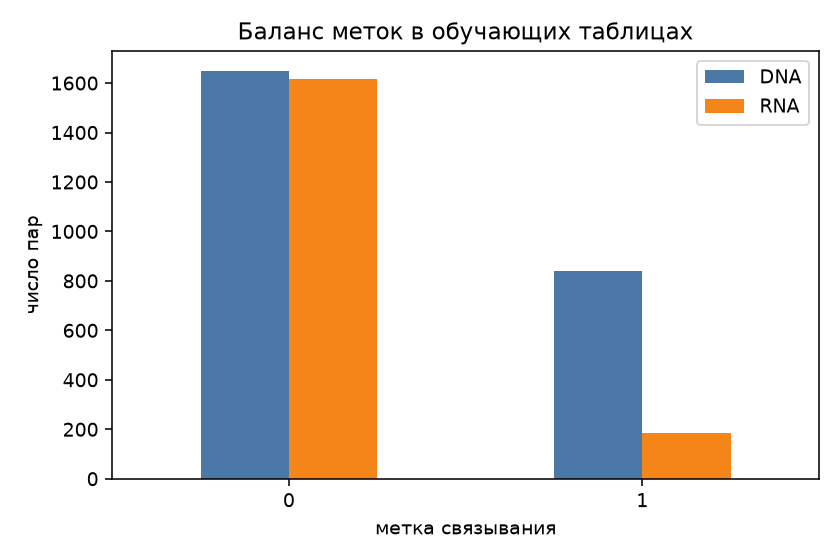

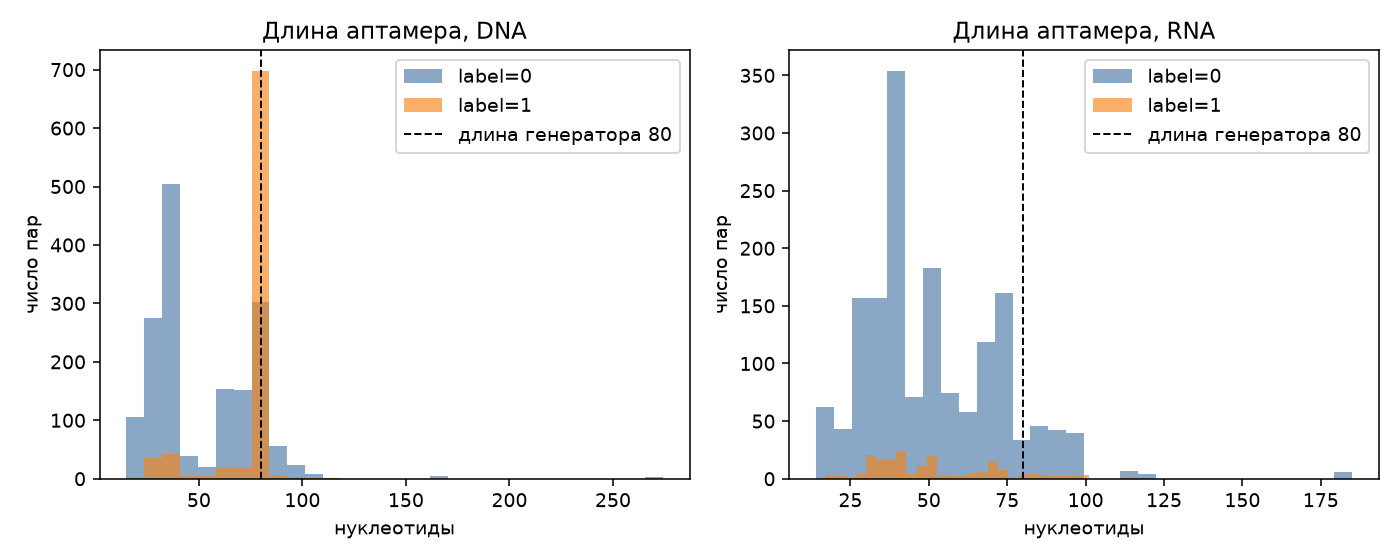

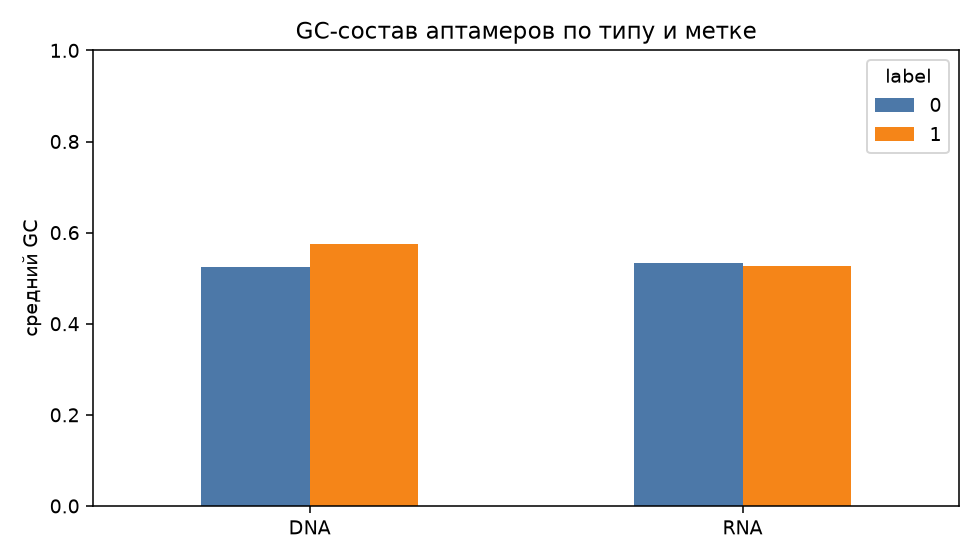

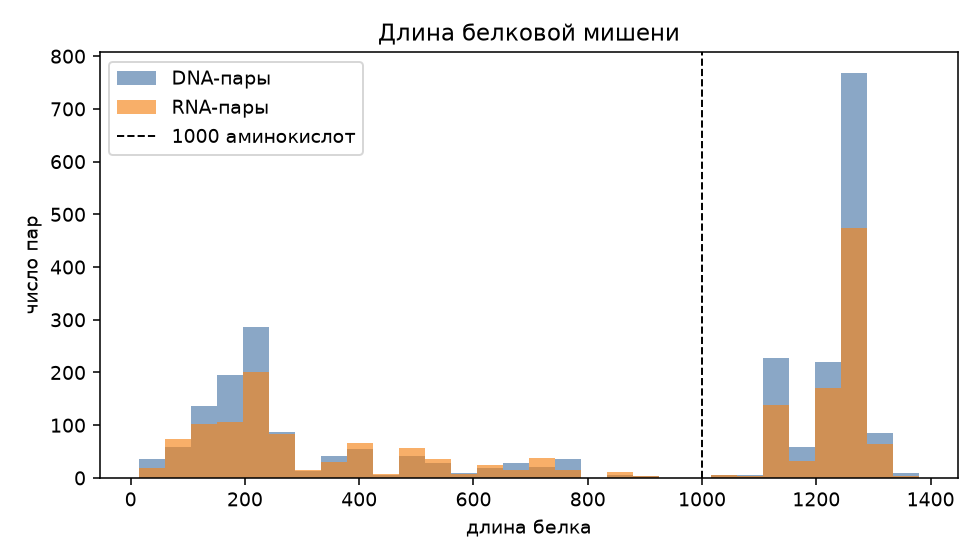

In [2]:
display(Image("figures/label_balance.png"))
display(Image("figures/aptamer_length.png"))
display(Image("figures/gc_by_label.png"))
display(Image("figures/protein_length.png"))

## Качество

Генератор кодирует последовательность в 80 позиций и обрезает хвост. Длиннее 80 нуклеотидов 115 DNA-строк и 179 RNA-строк. Для этих пар в генератор попадает только префикс.

Белок длиннее 1000 аминокислот у 1381 DNA-пар (56%) и у 895 RNA-пар (50%). Для ESMFold это зона отказов, дальше пайплайн уходит в AlphaFold DB.

21 DNA-аптамер не содержит ни G, ни C. Из них 20 с меткой 0. В RNA-таблице 42 строки с буквой T, хотя DNA/RNA в `preprocess_and_split.py` делится по наличию U. Из этих 42 строк 41 - негативы.

В `preprocess_and_split.py` задумано 3 синтетических негатива на 1 позитив. В файлах репозитория вышло 1.96 для DNA и 8.70 для RNA. `Aptamers_and_targets.csv` в репозитории нет, так что не видно, на каком шаге соотношение разъехалось. В лаборатории эти негативы никто не проверял.

У DNA 138 аптамеров ни разу не имеют метку 1, но генератор все равно берет все уникальные `apt_seq`.

## Шортлист и докинг

Первая строка `candidates_for_docking.csv` - текст `cat candidates_for_docking.csv`, не заголовок. Дальше 29 пар, 28 уникальных аптамеров и 12 белков. Имена есть у 10 мишеней. Две строки без `target_name` имеют `true_label = 0` (`candidate_006`, `candidate_014`). Остальные 27 строк помечены как реальные связывания.

Вероятности APIPred и AptaTrans на всех 29 строках равны 1.0. Минимальная вероятность AptaNet - 0.645. Внутри консенсуса первые две модели кандидатов не сортируют.

19 из 29 аптамеров шортлиста уже есть в `train_rna_dataset.csv`. В DNA-таблице после замены U на T не нашелся ни один. По этому файлу не видно, как модели ведут себя на новых последовательностях.

В `final_ranked_candidates_hdock.csv` 123 строки и 25 кандидатов, по 3-9 конформеров на кандидата. Четырех кандидатов из шортлиста в докинге нет: `candidate_018`, `candidate_022`, `candidate_026`, `candidate_029`. Docking score от -1246.21 до -244.95, медиана -396.27. Лучший score не выше -1000 только у трех кандидатов.

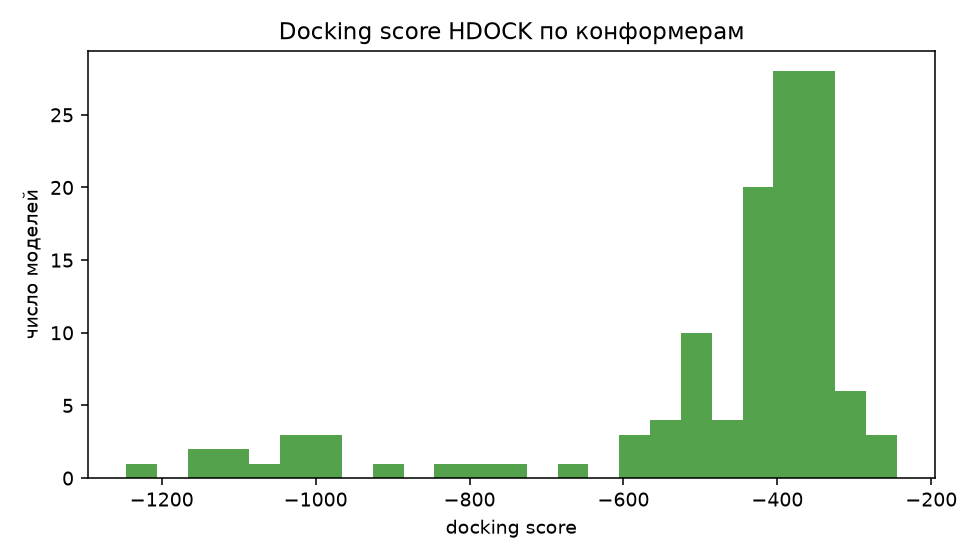

junk line: cat candidates_for_docking.csv
true labels: {'0': 2, '1': 27}
proba min: {'proba_1_apipred': 1.0, 'proba_1_aptatrans': 1.0, 'proba_1_aptanet': 0.6452}
docking: {'rows': 123, 'unique_candidates': 25, 'models_per_candidate': {'count': 25.0, 'mean': 4.92, 'std': 1.35, 'min': 3.0, '25%': 4.0, '50%': 5.0, '75%': 5.0, 'max': 9.0}, 'score_min': -1246.21, 'score_max': -244.95, 'score_median': -396.27, 'best_per_candidate_median': -424.95, 'candidates_best_le_minus_1000': 3}


In [3]:
display(Image("figures/docking_scores.png"))
print("junk line:", summary["candidates"]["junk_first_line"])
print("true labels:", summary["candidates"]["true_label_counts"])
print("proba min:", summary["candidates"]["proba_min"])
print("docking:", summary["docking"])

## Выводы для следующего этапа

1. Классификаторы нельзя проверять случайным разбиением строк. Один и тот же аптамер и один и тот же белок повторяются. Для RNA отдельно смотрим белки, у которых есть обе метки: там позитивов около половины, а не 10%.
2. Accuracy на полной RNA-таблице раздувают легкие негативы. В критерии успеха оставляем F1 класса "связывается" и ROC AUC.
3. Генератор надо сравнивать со случайными последовательностями того же GC и той же длины на аптамерах, которые не входили в обучение. Текущие GC, MFE и Левенштейн в README посчитаны на тех же данных, на которых модель училась.
4. Перед докингом надо поправить CSV шортлиста. Белки длиннее 1000 аминокислот лучше сразу помечать: ESMFold на них часто не проходит.
5. Имен и контактов в таблицах нет, только последовательности и названия мишеней. Обезличивать нечего. Это расчет для исследователя, не медицинское заключение.